# 02 - External data: economic calendar, Fear & Greed, news tone

Sources:
- **US macro calendar** (FOMC decisions, CPI, jobs report, PPI, PCE, GDP): official 2026 schedules from
  federalreserve.gov, bls.gov and bea.gov. Releases are scheduled in advance, so using them is not a leak.
- **Crypto Fear & Greed index** (alternative.me, daily). We use the value of the previous UTC day.
- **GDELT news tone** (free news API). We try it; it may refuse requests (rate limit).
- CoinDesk news sentiment needs a paid key and Twitter/X needs a paid API, so they are not used.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

In [2]:
from pricing.data import load_orders
from pricing.external import (macro_calendar, calendar_features, fear_greed, fear_greed_features,
                              gdelt_hourly_tone, news_features)
train, valid = load_orders("train"), load_orders("valid")
cal = macro_calendar()
print(cal.groupby("event").size().to_string())
cal.head(10)

event
CPI     12
FOMC     8
GDP      8
Jobs    12
PCE     10
PPI     13


,event,time_et,time_utc,source
0,Jobs,2026-01-09 08:30,2026-01-09 13:30:00,https://www.bls.gov/schedule/2026/home.htm
1,CPI,2026-01-13 08:30,2026-01-13 13:30:00,https://www.bls.gov/schedule/2026/home.htm
2,PPI,2026-01-14 08:30,2026-01-14 13:30:00,https://www.bls.gov/schedule/2026/home.htm
3,PCE,2026-01-22 08:30,2026-01-22 13:30:00,https://www.bea.gov/news/schedule/full
4,FOMC,2026-01-28 14:00,2026-01-28 19:00:00,https://www.federalreserve.gov/monetarypolicy/...
5,PPI,2026-01-30 08:30,2026-01-30 13:30:00,https://www.bls.gov/schedule/2026/home.htm
6,Jobs,2026-02-11 08:30,2026-02-11 13:30:00,https://www.bls.gov/schedule/2026/home.htm
7,CPI,2026-02-13 08:30,2026-02-13 13:30:00,https://www.bls.gov/schedule/2026/home.htm
8,PCE,2026-02-20 08:30,2026-02-20 13:30:00,https://www.bea.gov/news/schedule/full
9,GDP,2026-02-20 08:30,2026-02-20 13:30:00,https://www.bea.gov/news/schedule/full


Fear & Greed: 3174 days, 2018-02-01 to 2026-10-14


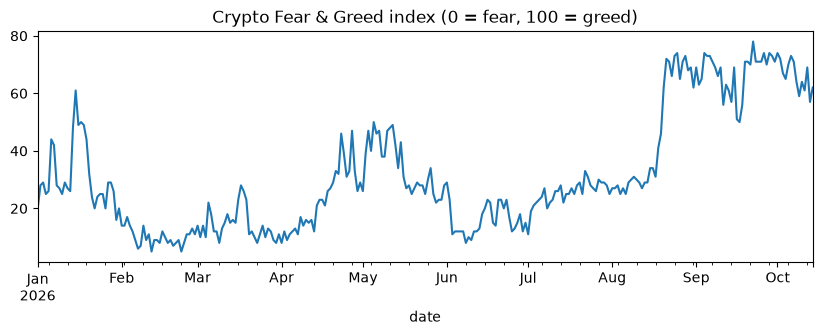

In [3]:
fng = fear_greed(cache=False)
print(f"Fear & Greed: {len(fng)} days, {fng.date.min().date()} to {fng.date.max().date()}")
ax = fng.set_index("date").loc["2026-01-01":, "fng"].plot(figsize=(10, 3), title="Crypto Fear & Greed index (0 = fear, 100 = greed)")
plt.show()

## GDELT news tone

First a probe of two weeks. If GDELT refuses, the news features are not used, and the report says so.

In [4]:
status = {}
news, msg = gdelt_hourly_tone("2026-01-25", "2026-02-08", max_tries=2)
status["gdelt_probe"] = msg
if news is not None:
    news, msg = gdelt_hourly_tone("2026-01-25", "2026-10-14")
    status["gdelt_full"] = msg
status["news_available"] = news is not None
print(status)

{'gdelt_probe': 'GDELT refused requests (last HTTP 429); stopped at 2026-02-01', 'news_available': False}


In [5]:
ext_train = calendar_features(train, cal).join(fear_greed_features(train, fng))
ext_valid = calendar_features(valid, cal).join(fear_greed_features(valid, fng))
if news is not None:
    ext_train = ext_train.join(news_features(train, news))
    ext_valid = ext_valid.join(news_features(valid, news))
ext_train.to_parquet(OUT / "external_train.parquet")
ext_valid.to_parquet(OUT / "external_valid.parquet")
(OUT / "external_status.json").write_text(json.dumps(status, indent=1))
ext_train.describe().T[["mean", "min", "max"]]

,mean,min,max
hours_to_event,95.096,0.004,168.000
hours_since_event,92.548,0.000,168.000
event_in_window,0.063,0.000,1.000
fng,0.231,0.050,0.500
fng_change7,0.001,-0.240,0.230


## Do payouts change when a release falls inside the protection window?

Ratio = total payout / total (base price x size), training orders with a base price.

In [6]:
d = train[train["has_outcome"] & train["base"].notna()].join(ext_train)
t = d.groupby("event_in_window").apply(lambda g: pd.Series({
    "orders": len(g), "payout / base": g["post_payout_usd"].sum() / (g["base"] * g["qty"]).sum()}), include_groups=False)
t.index = t.index.map({0: "no release in window", 1: "release in window"})
t.to_csv(OUT / "eda_events.csv")
t.round(2)

,orders,payout / base
event_in_window,,
no release in window,"5,702.000",1.350
release in window,317.000,1.820
